# Кейс 3. Бинарная классификация отклика клиентов на банковский депозит.

Инициализация и обучение CatBoost...
0:	learn: 0.6776945	test: 0.6770743	best: 0.6770743 (0)	total: 193ms	remaining: 1m 36s
100:	learn: 0.5289125	test: 0.5194708	best: 0.5194708 (100)	total: 3.32s	remaining: 13.1s
200:	learn: 0.5201696	test: 0.5171383	best: 0.5171025 (197)	total: 6.59s	remaining: 9.8s
300:	learn: 0.5005177	test: 0.5140990	best: 0.5140001 (296)	total: 10.1s	remaining: 6.7s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.5134686342
bestIteration = 317

Shrink model to first 318 iterations.

Отчет о классификации (CatBoost)
              precision    recall  f1-score   support

   Отказ (0)       0.95      0.87      0.91      9137
Согласие (1)       0.39      0.66      0.49      1160

    accuracy                           0.85     10297
   macro avg       0.67      0.76      0.70     10297
weighted avg       0.89      0.85      0.86     10297

ROC-AUC: 0.813
PR-AUC: 0.489


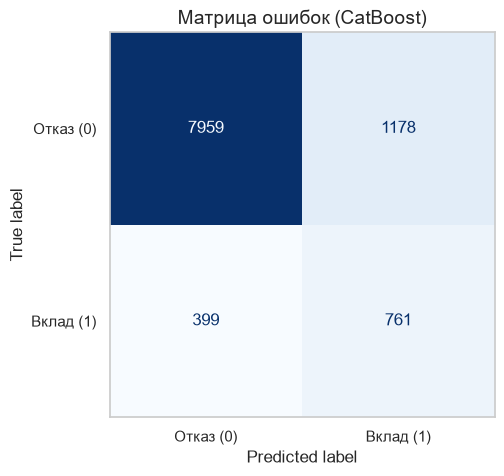

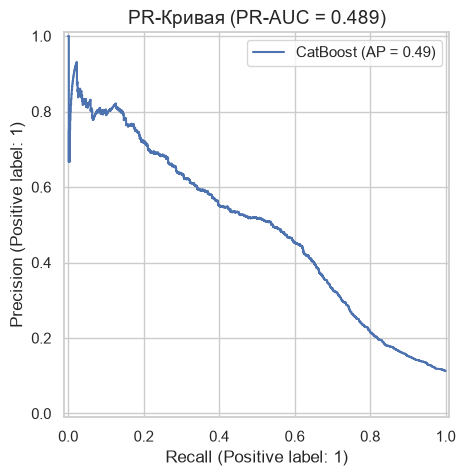

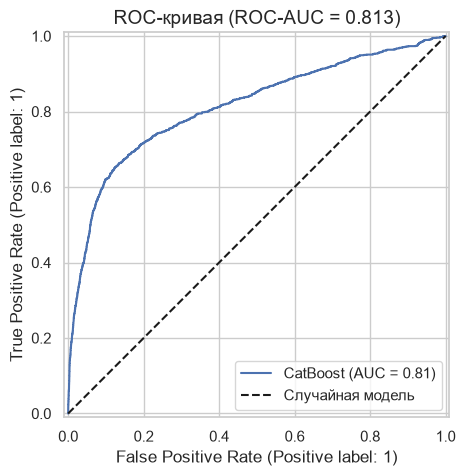

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier
from sklearn.metrics import (classification_report, roc_auc_score, average_precision_score, 
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

# 1. Настройка графиков
sns.set_theme(style='whitegrid', context='notebook')

# 2. Загрузка данных
df = pd.read_csv('bank-additional-full.csv', sep=None, engine='python')

# 3. Очистка и инженерия признаков (Feature Engineering)
# Удаляем целевую переменную, утечку (duration), мусор (default) и дубликаты экономики
X = df.drop(columns=['y', 'duration', 'default', 'emp.var.rate', 'nr.employed'])
y = (df['y'] == 'yes').astype(int)

# Добавляем новый признак
X['is_contacted_before'] = (X['pdays'] != 999).astype(int)

# 4. Составляем список категориальных признаков для CatBoost
cat_features = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

# 5. Разбиение на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

# Catboost
print("Инициализация и обучение CatBoost...")
cb_model = CatBoostClassifier(
    iterations=500,                 # Максимальное количество деревьев
    learning_rate=0.05,             # Скорость обучения
    depth=6,                        # Глубина деревьев
    cat_features=cat_features,      # Передаем список текстовых колонок напрямую!
    auto_class_weights='Balanced',  # Автоматическая балансировка классов (0 и 1)
    random_seed=42,
    verbose=100                     # Выводить лог обучения каждые 100 шагов
)

# Обучаем модель. 
# Используем eval_set для ранней остановки (early_stopping), если модель начнет переобучаться
cb_model.fit(
    X_train, y_train,
    eval_set=(X_test, y_test),
    early_stopping_rounds=50
)

# 6. Предсказания
y_pred = cb_model.predict(X_test)
y_proba = cb_model.predict_proba(X_test)[:, 1]

# Оценка метрик и вывод графиков
print("\nОтчет о классификации (CatBoost)")
print(classification_report(y_test, y_pred, target_names=["Отказ (0)", "Согласие (1)"]))

roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)
print(f"ROC-AUC: {roc_auc:.3f}")
print(f"PR-AUC: {pr_auc:.3f}")

# График 1: Матрица ошибок
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Отказ (0)", "Вклад (1)"], cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Матрица ошибок (CatBoost)", fontsize=14)
ax.grid(False)
plt.show()

# График 2: PR-кривая
fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(
    y_test, y_proba, name='CatBoost', ax=ax
)
ax.set_title(f"PR-Кривая (PR-AUC = {pr_auc:.3f})", fontsize=14)
ax.legend(loc="upper right")
plt.show()

# График 3: ROC-кривая
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y_test, y_proba, name='CatBoost', ax=ax
)
ax.plot([0, 1], [0, 1], 'k--', label='Случайная модель')
ax.set_title(f"ROC-кривая (ROC-AUC = {roc_auc:.3f})", fontsize=14)
ax.legend(loc="lower right")
plt.show()